# Entrenamiento, ajuste y evaluación de los cuatro modelos

Desarrollé los cuatro modelos del experimento, uno por bloque: **SVM**, **árbol de decisión**, **Random
Forest** (bagging) y **XGBoost** (boosting). Usé en todos las mismas particiones del notebook 03, los
evalué con las mismas métricas sobre el mismo conjunto de prueba y los medí con el mismo cronómetro, para
que las diferencias entre ellos vengan del modelo y no del procedimiento.

**Regla de oro del ajuste.** Elegí los hiperparámetros únicamente con datos de entrenamiento (validación
cruzada, evaluación out-of-bag o una partición interna de validación). Usé el conjunto de prueba una sola
vez por modelo, al final de su bloque, para reportar el resultado.

**Cómo medí el costo computacional.**

- *Tiempo de entrenamiento*: segundos que tarda el ajuste final del `Pipeline` completo (preprocesamiento
  más modelo) sobre las 36.168 filas de entrenamiento. Repetí el ajuste tres veces y reporté la mediana,
  junto con el mínimo y el máximo, porque el tiempo de una sola corrida cambia con la carga de la
  máquina. En los modelos con paralelismo interno usé un solo núcleo (`n_jobs=1`) en este paso, para que
  la comparación no dependa de cuántos núcleos tenga el equipo. La búsqueda de hiperparámetros sí usó
  todos los núcleos disponibles y su tiempo no forma parte del costo comparado.
- *Tiempo de predicción*: segundos que tarda `predict` del `Pipeline` completo sobre las 9.043 filas de
  prueba, también como mediana de varias repeticiones (tres en el SVM, que es lento, y más en los modelos
  rápidos).
- *Entorno*: registré el procesador, la memoria y las versiones de las librerías en `entorno.json`, porque
  los tiempos absolutos solo tienen sentido junto con la máquina donde se midieron.

**Cómo medí la estabilidad y el sesgo-varianza.** Además de las cinco métricas sobre prueba, calculé para
cada modelo un intervalo de confianza del 95 % por bootstrap sobre las predicciones de prueba (1000
remuestreos), las métricas sobre una muestra de entrenamiento del mismo tamaño que prueba (la brecha
entre ambas indica sobreajuste) y la proporción de clientes contratadores que queda dentro del 20 % de
clientes con mayor puntaje.

### Entorno y persistencia de resultados

En la celda siguiente fijé tres cosas que condicionan la reproducibilidad del experimento.

**Semilla fija.** Usé `RANDOM_STATE = 42` en la partición train/test y en el ajuste de todos los
modelos. Sin ella, cada ejecución produciría particiones distintas y las métricas no serían
comparables entre corridas ni verificables por un tercero.

**Persistencia en Google Drive.** Escribí los resultados en `MyDrive/bank_marketing` y no en el
disco temporal de Colab, que se borra al cerrar la sesión. El notebook 03 deja las particiones
preparadas y los notebooks 04 y 05 las consumen tal cual, de modo que todos operan sobre exactamente
los mismos datos. Si el montaje no se completa, la celda interrumpe la ejecución en lugar de escribir
en una ubicación volátil. Fuera de Colab no hace falta Drive, y los resultados se escriben en la
carpeta del repositorio (los gráficos en `splits/`).

**Registro de las figuras.** La función `guardar` escribe cada gráfico en `splits/` como PNG a 200
dpi. La invoco antes de `plt.show()`, porque mostrar la figura vacía el buffer de matplotlib y el
archivo saldría en blanco.

In [1]:
import os, io, time, json, zipfile, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

EN_DRIVE = False
try:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.isdir("/content/drive/MyDrive"):
        raise RuntimeError(
            "Drive no quedó montado. Vuelve a ejecutar esta celda y autoriza el acceso "
            "en la ventana emergente."
        )
    RUTA = "/content/drive/MyDrive/bank_marketing"
    EN_DRIVE = True
except ImportError:
    RUTA = os.path.abspath(".." if os.path.basename(os.getcwd()) == "notebooks" else ".")

CARPETA_SPLITS = os.path.join(RUTA, "splits")
os.makedirs(CARPETA_SPLITS, exist_ok=True)

def guardar(nombre):
    destino = os.path.join(CARPETA_SPLITS, nombre + ".png")
    plt.savefig(destino, dpi=200, bbox_inches="tight", facecolor="white")
    print("Gráfico guardado:", destino)

print("Guardando en Google Drive" if EN_DRIVE else "Google Drive no disponible: guardando localmente")
print("Ruta de trabajo:", RUTA)

Google Drive no disponible: guardando localmente
Ruta de trabajo: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing


## Preparación común

Cargué las particiones y definí los dos preprocesadores: el escalado (solo para el SVM, con el escalador
que eligió el notebook 03) y el no escalado (para los tres modelos de árboles). Los dos terminan en
one-hot de las categóricas. Ambos viven dentro de un `Pipeline`, así que se ajustan únicamente con los
datos de entrenamiento que reciba cada pipeline.

También separé una **muestra de entrenamiento del mismo tamaño que prueba** (9.043 filas). Evaluar sobre
ella, en vez de sobre todo el entrenamiento, mantiene el costo de predicción del SVM bajo control y
permite comparar la brecha entre entrenamiento y prueba con el mismo número de filas.

In [2]:
import joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, QuantileTransformer, OneHotEncoder
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split, cross_validate
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from xgboost import XGBClassifier

paquete = joblib.load(os.path.join(RUTA, "datos_preparados.joblib"))
X_train, X_test = paquete["X_train"], paquete["X_test"]
y_train, y_test = paquete["y_train"], paquete["y_test"]
cols_num, cols_cat = paquete["cols_num"], paquete["cols_cat"]
escalador_svm = paquete["escalador_svm"]
print("Train:", X_train.shape, "| Test:", X_test.shape, "| Escalador del SVM:", escalador_svm)

def codificador():
    return OneHotEncoder(handle_unknown="ignore", drop="if_binary")

def prep_sin_escalar():
    return ColumnTransformer([("num", "passthrough", cols_num), ("cat", codificador(), cols_cat)])

def prep_escalado():
    escaladores = {"estandar": StandardScaler(), "robusto": RobustScaler(),
                   "cuantil": QuantileTransformer(output_distribution="normal", n_quantiles=500, random_state=RANDOM_STATE)}
    return ColumnTransformer([("num", escaladores[escalador_svm], cols_num), ("cat", codificador(), cols_cat)])

validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
puntuaciones = {"f1": "f1", "roc_auc": "roc_auc"}
X_tr_eval, _, y_tr_eval, _ = train_test_split(
    X_train, y_train, train_size=len(X_test), stratify=y_train, random_state=RANDOM_STATE)
peso_positivo = float((y_train == 0).sum() / (y_train == 1).sum())
print("Peso de la clase positiva (scale_pos_weight):", round(peso_positivo, 3))

Train: (36168, 16) | Test: (9043, 16) | Escalador del SVM: estandar
Peso de la clase positiva (scale_pos_weight): 7.548


## Funciones de medición

Escribí la función `registrar` para que la evaluación sea idéntica en los cuatro modelos. Cronometra
`predict`, calcula las cinco métricas sobre prueba, las mismas sobre la muestra de entrenamiento, el
bootstrap, la matriz de confusión y la captura del 20 % superior, y persiste todo en
`resultados_modelos.json` y `puntajes_test.npz`, que consume el notebook 05. Escribí también
`ajustar_midiendo`, que repite el ajuste final tres veces y devuelve el primer modelo junto con la
mediana y el rango de los tiempos. Por último, registré el entorno de ejecución (procesador, memoria y
versiones) en `entorno.json`.

El umbral de decisión es el natural de cada modelo, que es el signo de la función de decisión en el SVM
y la probabilidad 0,5 en los demás. Como los cuatro se entrenan con ponderación de clases, 0,5 ya no
equivale a "predecir siempre la clase mayoritaria".

In [3]:
resultados, puntajes = {}, {}
os.makedirs(os.path.join(RUTA, "modelos"), exist_ok=True)

def puntaje(modelo, X):
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X)[:, 1]
    return modelo.decision_function(X)

def metricas(y, prediccion, score):
    return {"accuracy": float(accuracy_score(y, prediccion)),
            "precision": float(precision_score(y, prediccion, zero_division=0)),
            "recall": float(recall_score(y, prediccion, zero_division=0)),
            "f1": float(f1_score(y, prediccion, zero_division=0)),
            "roc_auc": float(roc_auc_score(y, score))}

def bootstrap(y, prediccion, score, repeticiones=1000):
    generador = np.random.default_rng(RANDOM_STATE)
    y = np.asarray(y)
    f1s, aucs = [], []
    for _ in range(repeticiones):
        i = generador.integers(0, len(y), len(y))
        f1s.append(f1_score(y[i], prediccion[i], zero_division=0))
        aucs.append(roc_auc_score(y[i], score[i]))
    return {"ic95_f1": [float(np.percentile(f1s, 2.5)), float(np.percentile(f1s, 97.5))],
            "ic95_auc": [float(np.percentile(aucs, 2.5)), float(np.percentile(aucs, 97.5))],
            "desv_f1_bootstrap": float(np.std(f1s)), "desv_auc_bootstrap": float(np.std(aucs))}

def captura_top20(y, score):
    y = np.asarray(y)
    mejores = np.argsort(-score)[: int(0.2 * len(y))]
    return float(y[mejores].sum() / y.sum())

def ajustar_midiendo(construir, repeticiones=3):
    tiempos, primero = [], None
    for _ in range(repeticiones):
        candidato = construir()
        inicio = time.perf_counter()
        candidato.fit(X_train, y_train)
        tiempos.append(time.perf_counter() - inicio)
        if primero is None:
            primero = candidato
    return primero, float(np.median(tiempos)), [float(min(tiempos)), float(max(tiempos))]

def persistir():
    with open(os.path.join(RUTA, "resultados_modelos.json"), "w", encoding="utf-8") as f:
        json.dump(resultados, f, ensure_ascii=False, indent=1)
    np.savez(os.path.join(RUTA, "puntajes_test.npz"), y_test=np.asarray(y_test), **puntajes)

def registrar(nombre, modelo, segundos_entrenamiento, repeticiones_prediccion, umbral, extra=None):
    tiempos, prediccion = [], None
    for _ in range(repeticiones_prediccion):
        inicio = time.perf_counter()
        p = modelo.predict(X_test)
        tiempos.append(time.perf_counter() - inicio)
        if prediccion is None:
            prediccion = p
    s_test = puntaje(modelo, X_test)
    s_tr = puntaje(modelo, X_tr_eval)
    p_tr = (s_tr > umbral).astype(int)
    registro = {
        "tiempo_entrenamiento_s": float(segundos_entrenamiento),
        "tiempo_prediccion_s": float(np.median(tiempos)),
        "rango_prediccion_s": [float(min(tiempos)), float(max(tiempos))],
        "clientes_predichos": int(len(X_test)),
        "test": metricas(y_test, prediccion, s_test),
        "train_muestra": metricas(y_tr_eval, p_tr, s_tr),
        "matriz_confusion": confusion_matrix(y_test, prediccion).tolist(),
        "captura_top20": captura_top20(y_test, s_test),
    }
    registro.update(bootstrap(y_test, prediccion, s_test))
    if extra:
        registro.update(extra)
    resultados[nombre] = registro
    puntajes[nombre] = s_test
    persistir()
    joblib.dump(modelo, os.path.join(RUTA, "modelos", nombre + ".joblib"), compress=3)
    t = registro["test"]
    print(f"{nombre}: entrenamiento {registro['tiempo_entrenamiento_s']:.2f} s | predicción {registro['tiempo_prediccion_s']:.3f} s")
    print(f"  test -> accuracy {t['accuracy']:.4f} | precision {t['precision']:.4f} | recall {t['recall']:.4f} | "
          f"F1 {t['f1']:.4f} | AUC {t['roc_auc']:.4f}")
    print(f"  train (muestra) -> F1 {registro['train_muestra']['f1']:.4f} | AUC {registro['train_muestra']['roc_auc']:.4f}")
    print(f"  IC 95 % F1 {registro['ic95_f1'][0]:.4f} a {registro['ic95_f1'][1]:.4f} | captura top 20 % {registro['captura_top20']:.3f}")

def importancia_por_variable(preparador, valores):
    acumulado = {}
    for nombre, valor in zip(preparador.get_feature_names_out(), valores):
        origen = nombre.split("__", 1)[1]
        for col in cols_cat:
            if nombre.startswith("cat__" + col + "_"):
                origen = col
                break
        acumulado[origen] = acumulado.get(origen, 0.0) + float(valor)
    return pd.Series(acumulado).sort_values(ascending=False)

def graficar_importancia(serie, titulo, archivo, color):
    tope = serie.head(12).sort_values()
    plt.figure(figsize=(7, 5))
    plt.barh(tope.index, tope.values, color=color)
    plt.xlabel("Importancia (suma por variable original)")
    plt.title(titulo)
    plt.tight_layout()
    guardar(archivo)
    plt.show()

In [4]:
import platform, sys
import sklearn, xgboost
try:
    import psutil
    memoria_gb = round(psutil.virtual_memory().total / 2 ** 30, 1)
except ImportError:
    memoria_gb = None

entorno = {"sistema": platform.platform(), "procesador": platform.processor(), "nucleos_logicos": os.cpu_count(),
           "memoria_gb": memoria_gb, "python": sys.version.split()[0], "numpy": np.__version__,
           "pandas": pd.__version__, "scikit_learn": sklearn.__version__, "xgboost": xgboost.__version__}
with open(os.path.join(RUTA, "entorno.json"), "w", encoding="utf-8") as f:
    json.dump(entorno, f, ensure_ascii=False, indent=1)
for clave, valor in entorno.items():
    print(f"{clave}: {valor}")

sistema: Windows-11-10.0.26200-SP0
procesador: Intel64 Family 6 Model 154 Stepping 3, GenuineIntel
nucleos_logicos: 16
memoria_gb: 31.7
python: 3.12.10
numpy: 2.2.6
pandas: 3.0.3
scikit_learn: 1.8.0
xgboost: 3.4.1


## Línea base

Registré un clasificador que siempre responde `no` como piso, porque cualquier modelo que no lo supere en
F1 y en AUC no aporta nada. Lo evalué con el mismo procedimiento que los demás, para que el costo de
referencia (prácticamente cero) también quede en la tabla.

In [5]:
base = DummyClassifier(strategy="most_frequent")
inicio = time.perf_counter()
base.fit(X_train, y_train)
registrar("Baseline", base, time.perf_counter() - inicio, 5, 0.5)

Baseline: entrenamiento 0.00 s | predicción 0.000 s
  test -> accuracy 0.8830 | precision 0.0000 | recall 0.0000 | F1 0.0000 | AUC 0.5000
  train (muestra) -> F1 0.0000 | AUC 0.5000
  IC 95 % F1 0.0000 a 0.0000 | captura top 20 % 0.207


**Lectura.** La línea base tiene F1 y AUC de piso (0 y 0,5), accuracy de 0,883 y un costo
prácticamente nulo. Ningún modelo debe compararse contra la accuracy de este modelo, sino contra su F1
y su AUC.

# Bloque 1: Máquina de vectores de soporte (SVM)

### Decisiones de diseño

**Kernel.** No asumí el kernel, lo comparé. El kernel lineal es el más barato y sirve de referencia; el
RBF puede curvar la frontera con un solo parámetro de forma (`gamma`); el polinómico agrega interacciones
explícitas de un grado dado. Los tres entraron en la misma búsqueda y la validación cruzada decidió, con
una tabla que permite ver cuánto gana cada uno sobre el lineal.

**Hiperparámetros.** `C` controla la penalización por errores de entrenamiento (valores altos ajustan
más y arriesgan sobreajuste) y `gamma` el alcance de cada punto en los kernels RBF y polinómico
(valores altos hacen fronteras más locales). Los busqué en rejilla con validación cruzada estratificada
de 5 particiones y seleccioné por F1 de la clase positiva.

**Submuestra para la búsqueda.** Un SVM con kernel tiene costo entre cuadrático y cúbico en el número
de filas. Buscar sobre las 36.168 filas multiplicaría el tiempo por decenas, así que evalué la rejilla
sobre una submuestra estratificada de 6.000 filas y reentrené el modelo final con todo el
entrenamiento. La limitación es real: con más datos, el valor óptimo de `C` tiende a subir levemente,
y el tiempo de búsqueda no es comparable con el de los demás modelos.

**Ponderación.** `class_weight="balanced"` hace que un error sobre un contratador pese como el
desbalance (aproximadamente 7,5 veces). Lo contrasté más abajo con el modelo sin ponderar.

**Tope de iteraciones.** Puse `max_iter` para evitar que un `C` alto con kernel lineal o polinómico deje
la búsqueda colgada. Si una combinación no converge dentro del tope, simplemente sale con peor puntaje.

In [6]:
submuestra_svm, _, y_submuestra_svm, _ = train_test_split(
    X_train, y_train, train_size=6000, stratify=y_train, random_state=RANDOM_STATE)

pipe_svm = Pipeline([
    ("prep", prep_escalado()),
    ("clf", SVC(class_weight="balanced", max_iter=300000, random_state=RANDOM_STATE))])

rejilla_svm = [
    {"clf__kernel": ["linear"], "clf__C": [0.01, 0.1, 1]},
    {"clf__kernel": ["rbf"], "clf__C": [0.3, 1, 3, 10], "clf__gamma": [0.001, 0.003, 0.01, 0.03]},
    {"clf__kernel": ["poly"], "clf__degree": [2, 3], "clf__C": [0.3, 1, 3], "clf__gamma": ["scale"]},
]

busqueda_svm = GridSearchCV(pipe_svm, rejilla_svm, scoring=puntuaciones, refit="f1",
                            cv=validacion, n_jobs=-1)
inicio = time.perf_counter()
busqueda_svm.fit(submuestra_svm, y_submuestra_svm)
segundos_busqueda_svm = time.perf_counter() - inicio

cv_svm = pd.DataFrame(busqueda_svm.cv_results_)
mejor_por_kernel = (cv_svm.groupby("param_clf__kernel")[["mean_test_f1", "mean_test_roc_auc"]].max().round(4)
                    .rename(columns={"mean_test_f1": "mejor_f1_cv", "mean_test_roc_auc": "mejor_auc_cv"}))
print(mejor_por_kernel, "\n")
print("Mejores hiperparámetros:", busqueda_svm.best_params_)
print("F1 en validación cruzada:", round(busqueda_svm.best_score_, 4))
print("Tiempo de búsqueda:", round(segundos_busqueda_svm, 1), "s sobre 6000 filas")

                   mejor_f1_cv  mejor_auc_cv
param_clf__kernel                           
linear                  0.3461        0.7270
poly                    0.3891        0.7312
rbf                     0.3941        0.7375 

Mejores hiperparámetros: {'clf__C': 1, 'clf__gamma': 0.03, 'clf__kernel': 'rbf'}
F1 en validación cruzada: 0.3941
Tiempo de búsqueda: 131.8 s sobre 6000 filas


**Lectura.** El kernel RBF es el mejor de los tres, aunque por poco. En validación cruzada obtiene un F1
de 0,394 y un AUC de 0,738, contra 0,389 y 0,731 del polinómico y 0,346 y 0,727 del lineal. La ventaja
sobre el lineal en F1 (cerca de 5 puntos) justifica el kernel no lineal, y la ventaja sobre el
polinómico es pequeña, así que me quedé con el RBF por tener un solo parámetro de forma. La
combinación elegida es `C = 1` y `gamma = 0,03`. La búsqueda sobre 6.000 filas tomó poco más de dos minutos.

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\04_svm_rejilla_c_gamma.png


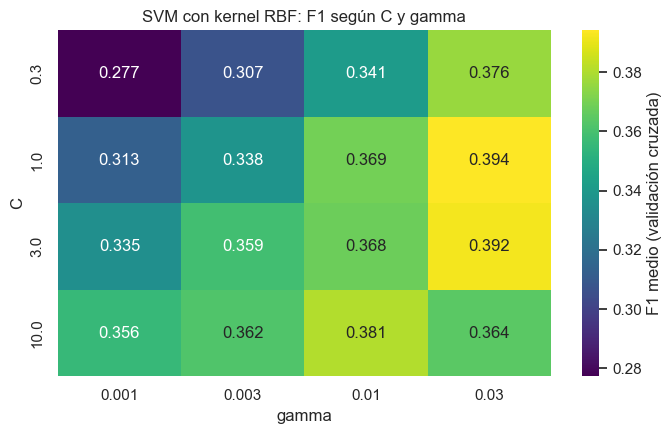

In [7]:
rbf = cv_svm[cv_svm["param_clf__kernel"] == "rbf"]
matriz_f1 = rbf.pivot_table(index="param_clf__C", columns="param_clf__gamma", values="mean_test_f1")

plt.figure(figsize=(7, 4.5))
sns.heatmap(matriz_f1, annot=True, fmt=".3f", cmap="viridis", cbar_kws={"label": "F1 medio (validación cruzada)"})
plt.xlabel("gamma")
plt.ylabel("C")
plt.title("SVM con kernel RBF: F1 según C y gamma")
plt.tight_layout()
guardar("04_svm_rejilla_c_gamma")
plt.show()

**Lectura.** El mapa muestra una zona buena en `gamma` alto con `C` entre 1 y 3 (F1 de 0,392 a 0,394) y
un deterioro cuando `C` sube a 10 con `gamma` alto (0,364), señal de sobreajuste. El valor elegido de
`gamma` está en el borde superior de la rejilla, así que es posible que un valor mayor mejore un poco el
resultado. Es una limitación de la búsqueda, anotada para las conclusiones.

### Efecto de la ponderación de clases

Repetí la validación cruzada con los mejores hiperparámetros, con y sin `class_weight="balanced"`, sobre
la misma submuestra. Si la ponderación no mejora el F1 o el recall de la clase positiva, no hay razón
para mantenerla.

In [8]:
filas = []
for etiqueta, peso in [("sin ponderar", None), ("balanced", "balanced")]:
    modelo = clone(pipe_svm).set_params(**busqueda_svm.best_params_, clf__class_weight=peso)
    r = cross_validate(modelo, submuestra_svm, y_submuestra_svm, cv=validacion,
                       scoring=["f1", "recall", "precision", "roc_auc"], n_jobs=-1)
    filas.append({"ponderación": etiqueta, "f1": r["test_f1"].mean(), "recall": r["test_recall"].mean(),
                  "precision": r["test_precision"].mean(), "auc": r["test_roc_auc"].mean()})
pd.DataFrame(filas).set_index("ponderación").round(4)

,f1,recall,precision,auc
ponderación,,,,
sin ponderar,0.2641,0.1666,0.6425,0.6974
balanced,0.3941,0.5726,0.3014,0.7375


**Lectura.** La ponderación de clases cambia por completo el modelo. Sin ponderar, el SVM casi no
detecta contratadores (recall de 0,167) y el F1 queda en 0,264. Con `balanced` el recall sube a 0,573,
la precisión baja de 0,643 a 0,301 y el F1 sube a 0,394. También mejora el AUC (de 0,697 a 0,738), es
decir, no solo mueve el umbral sino que ordena mejor a los clientes. Conservé la ponderación.

### Modelo final y costo

Reentrené el pipeline completo con los hiperparámetros elegidos sobre **todo** el entrenamiento y medí el
tiempo de ese ajuste. Es la parte más cara del experimento.

In [9]:
svm_final, segundos_svm, rango_svm = ajustar_midiendo(
    lambda: clone(pipe_svm).set_params(**busqueda_svm.best_params_))

soporte = int(svm_final.named_steps["clf"].n_support_.sum())
registrar("SVM", svm_final, segundos_svm, 3, 0.0,
          extra={"rango_entrenamiento_s": rango_svm, "parametros": {k: (v if not isinstance(v, np.generic) else v.item()) for k, v in busqueda_svm.best_params_.items()},
                 "vectores_soporte": soporte, "segundos_busqueda": float(segundos_busqueda_svm)})
print("Vectores de soporte:", soporte, f"({100 * soporte / len(X_train):.1f} % del entrenamiento)")

SVM: entrenamiento 135.27 s | predicción 18.507 s
  test -> accuracy 0.8276 | precision 0.3573 | recall 0.5926 | F1 0.4458 | AUC 0.7898
  train (muestra) -> F1 0.4564 | AUC 0.7970
  IC 95 % F1 0.4222 a 0.4670 | captura top 20 % 0.600
Vectores de soporte: 22779 (63.0 % del entrenamiento)


**Lectura.** Con todo el entrenamiento, el SVM alcanza un F1 de 0,446 y un AUC de 0,790 en prueba. Su
brecha con el entrenamiento es mínima (F1 de 0,456 en la muestra de entrenamiento), así que el modelo
está bien regularizado, pero su costo es el más alto del experimento junto con el Random Forest. El
entrenamiento tarda un par de minutos y la predicción sobre 9.043 clientes tarda varias decenas de
segundos (unos 2 milisegundos por cliente, frente a microsegundos del árbol). Un 63 % de los clientes de
entrenamiento terminó como vector de soporte, lo que explica por qué cada predicción es cara, ya que
debe compararse con todos ellos.

# Bloque 2: Árbol de decisión

### Decisiones de diseño

**Criterio de impureza.** `gini` y `entropy` miden qué tan mezclada queda una partición. Casi siempre
dan árboles parecidos, pero los comparé en la misma búsqueda en lugar de suponer que da igual.

**Control del sobreajuste.** Un árbol sin límites sigue dividiendo hasta memorizar cada fila de
entrenamiento. Lo frené con dos palancas, `max_depth` (cuántas preguntas encadenadas puede hacer) y
`min_samples_leaf` (cuántos clientes como mínimo debe tener cada hoja). Ambas entraron en la rejilla, y
grafiqué el F1 de entrenamiento contra el de validación para ver dónde empieza la brecha.

**Sin escalado.** Le di las numéricas tal cual, por lo demostrado en el notebook 03.

**Ponderación.** Usé `class_weight="balanced"` y lo contrasté contra el modelo sin ponderar con
validación cruzada.

In [10]:
pipe_arbol = Pipeline([
    ("prep", prep_sin_escalar()),
    ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))])

rejilla_arbol = {
    "clf__criterion": ["gini", "entropy"],
    "clf__max_depth": [3, 4, 5, 6, 8, 10, 15, None],
    "clf__min_samples_leaf": [1, 5, 20, 50, 100],
}

busqueda_arbol = GridSearchCV(pipe_arbol, rejilla_arbol, scoring=puntuaciones, refit="f1",
                              cv=validacion, n_jobs=-1, return_train_score=True)
busqueda_arbol.fit(X_train, y_train)

cv_arbol = pd.DataFrame(busqueda_arbol.cv_results_)
print("Mejores hiperparámetros:", busqueda_arbol.best_params_)
print("F1 en validación cruzada:", round(busqueda_arbol.best_score_, 4))

sin_control = cv_arbol[(cv_arbol["param_clf__max_depth"].isna()) & (cv_arbol["param_clf__min_samples_leaf"] == 1)]
print("\nÁrbol sin control del sobreajuste (max_depth=None, min_samples_leaf=1):")
print(sin_control[["param_clf__criterion", "mean_train_f1", "mean_test_f1"]].round(4).to_string(index=False))

Mejores hiperparámetros: {'clf__criterion': 'entropy', 'clf__max_depth': 10, 'clf__min_samples_leaf': 20}
F1 en validación cruzada: 0.4265

Árbol sin control del sobreajuste (max_depth=None, min_samples_leaf=1):
param_clf__criterion  mean_train_f1  mean_test_f1
                gini            1.0        0.3046
             entropy            1.0        0.3108


**Lectura.** La mejor combinación es criterio `entropy`, profundidad máxima 10 y al menos 20 clientes
por hoja, con un F1 de 0,427 en validación cruzada. El árbol sin ningún control memoriza el
entrenamiento (F1 de 1,00) pero cae a 0,305 con `gini` y 0,311 con `entropy` en validación. Controlar
el sobreajuste le hace ganar más de 11 puntos de F1.

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\04_arbol_sobreajuste.png


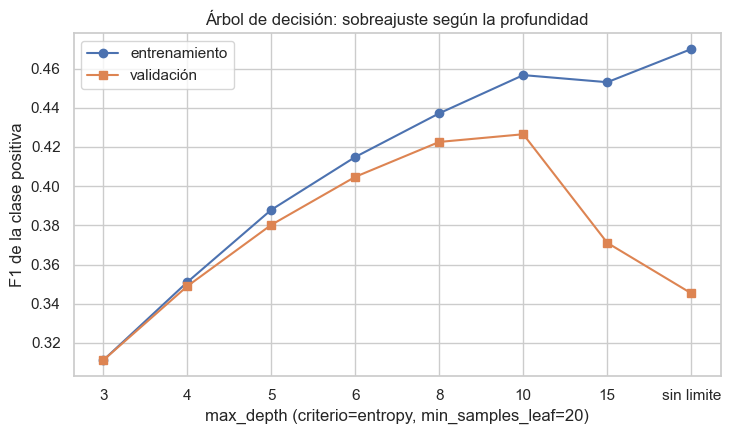

In [11]:
criterio = busqueda_arbol.best_params_["clf__criterion"]
hoja = busqueda_arbol.best_params_["clf__min_samples_leaf"]
curva = cv_arbol[(cv_arbol["param_clf__criterion"] == criterio) & (cv_arbol["param_clf__min_samples_leaf"] == hoja)].copy()
curva["profundidad"] = curva["param_clf__max_depth"].apply(lambda v: 40 if pd.isna(v) else v)
curva = curva.sort_values("profundidad")
etiquetas = [("sin limite" if p == 40 else int(p)) for p in curva["profundidad"]]

plt.figure(figsize=(7.5, 4.5))
plt.plot(range(len(curva)), curva["mean_train_f1"], marker="o", label="entrenamiento")
plt.plot(range(len(curva)), curva["mean_test_f1"], marker="s", label="validación")
plt.xticks(range(len(curva)), etiquetas)
plt.xlabel(f"max_depth (criterio={criterio}, min_samples_leaf={hoja})")
plt.ylabel("F1 de la clase positiva")
plt.title("Árbol de decisión: sobreajuste según la profundidad")
plt.legend()
plt.tight_layout()
guardar("04_arbol_sobreajuste")
plt.show()

**Lectura.** La curva de validación sube con la profundidad hasta 10 y luego se derrumba (de 0,427 a
0,371 con profundidad 15 y 0,345 sin límite), mientras el F1 de entrenamiento sigue subiendo. La
separación entre las dos líneas es la huella visual del sobreajuste, y el punto donde la validación
deja de mejorar es el que elegí.

In [12]:
filas = []
for etiqueta, peso in [("sin ponderar", None), ("balanced", "balanced")]:
    modelo = clone(pipe_arbol).set_params(**busqueda_arbol.best_params_, clf__class_weight=peso)
    r = cross_validate(modelo, X_train, y_train, cv=validacion, scoring=["f1", "recall", "precision", "roc_auc"], n_jobs=-1)
    filas.append({"ponderación": etiqueta, "f1": r["test_f1"].mean(), "recall": r["test_recall"].mean(),
                  "precision": r["test_precision"].mean(), "auc": r["test_roc_auc"].mean()})
pd.DataFrame(filas).set_index("ponderación").round(4)

,f1,recall,precision,auc
ponderación,,,,
sin ponderar,0.2931,0.194,0.6035,0.7537
balanced,0.4265,0.576,0.3401,0.7652


**Lectura.** La ponderación sube el F1 de 0,293 a 0,427 y el recall de 0,194 a 0,576, a costa de
bajar la precisión (de 0,604 a 0,340). El AUC también mejora (0,754 a 0,765). Conservé la ponderación.

### Modelo final, costo e interpretación

Ajusté el árbol con los mejores hiperparámetros sobre todo el entrenamiento. La interpretación tiene dos
partes. Una es el diagrama de los primeros niveles, que muestra las preguntas concretas que hace el
modelo. La otra es la importancia de variables, que agregué por variable original (las columnas one-hot
de una misma categórica se suman para que `job` aparezca como una sola variable y no como doce).

In [13]:
arbol_final, segundos_arbol, rango_arbol = ajustar_midiendo(
    lambda: clone(pipe_arbol).set_params(**busqueda_arbol.best_params_))

clf_arbol = arbol_final.named_steps["clf"]
registrar("Arbol", arbol_final, segundos_arbol, 20, 0.5,
          extra={"rango_entrenamiento_s": rango_arbol, "parametros": {k: (None if (isinstance(v, float) and np.isnan(v)) else v) for k, v in busqueda_arbol.best_params_.items()},
                 "profundidad": int(clf_arbol.get_depth()), "hojas": int(clf_arbol.get_n_leaves())})
print("Profundidad real:", clf_arbol.get_depth(), "| Hojas:", clf_arbol.get_n_leaves())

Arbol: entrenamiento 0.60 s | predicción 0.050 s
  test -> accuracy 0.8143 | precision 0.3358 | recall 0.6002 | F1 0.4307 | AUC 0.7800
  train (muestra) -> F1 0.4480 | AUC 0.8080
  IC 95 % F1 0.4079 a 0.4531 | captura top 20 % 0.595
Profundidad real: 10 | Hojas: 216


**Lectura.** El árbol final tiene profundidad 10 y 216 hojas. En prueba obtiene un F1 de 0,431 y un AUC
de 0,780, la peor combinación de los cuatro, pero entrena en menos de un segundo y predice los 9.043 clientes
en unas pocas centésimas de segundo. Su brecha con el entrenamiento es pequeña (F1 de 0,448 contra 0,431).

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\04_arbol_estructura.png


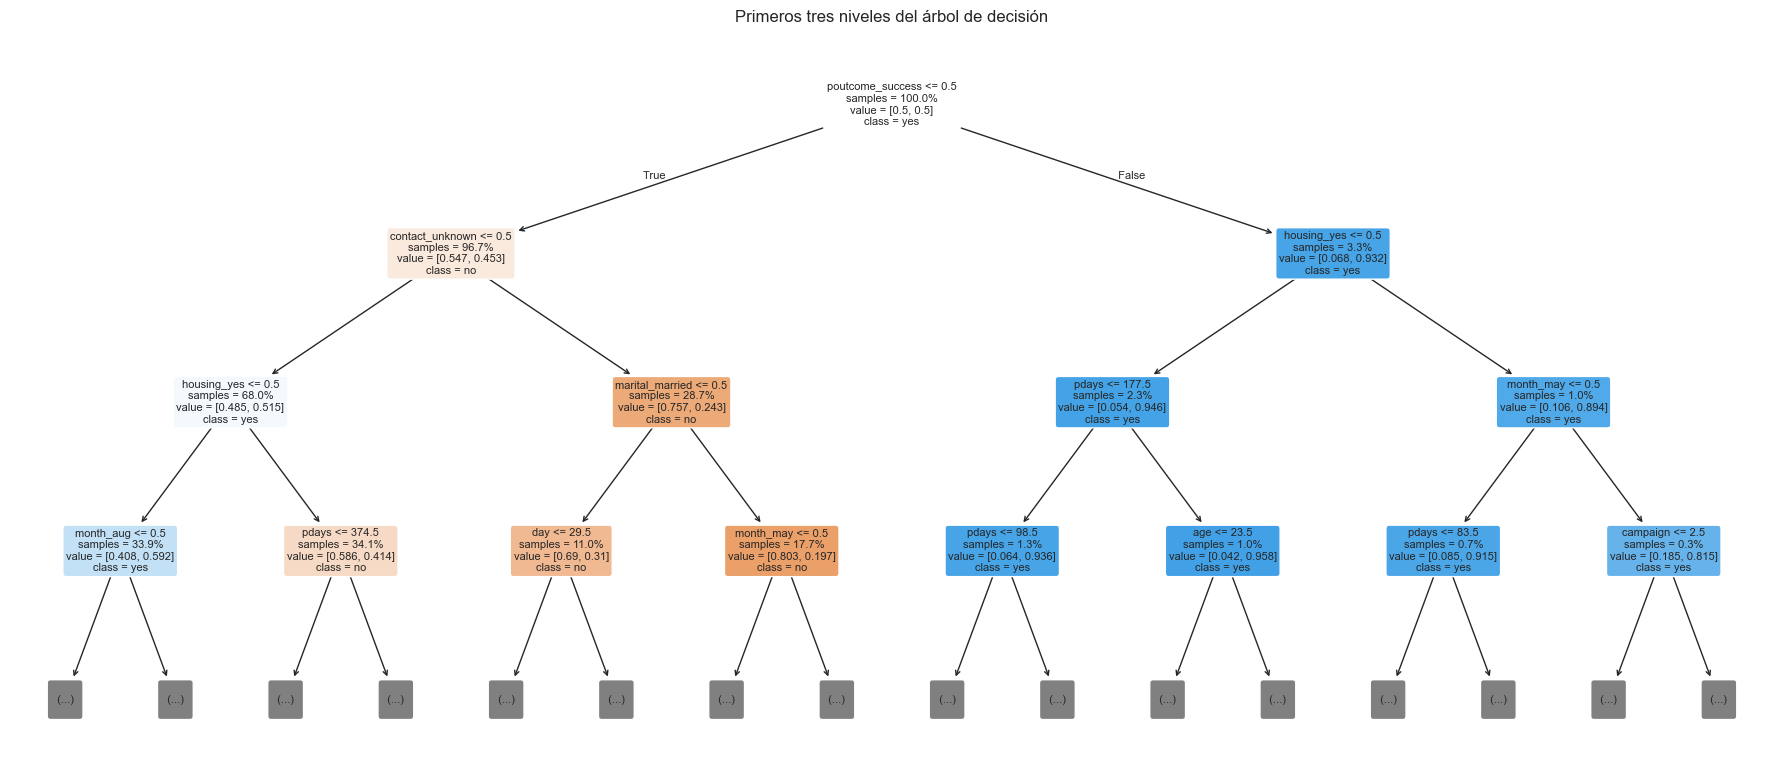

poutcome    0.2648
month       0.1967
contact     0.1359
day         0.1002
balance     0.0638
housing     0.0626
age         0.0487
pdays       0.0441
campaign    0.0334
marital     0.0267
dtype: float64
Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\04_arbol_importancia.png


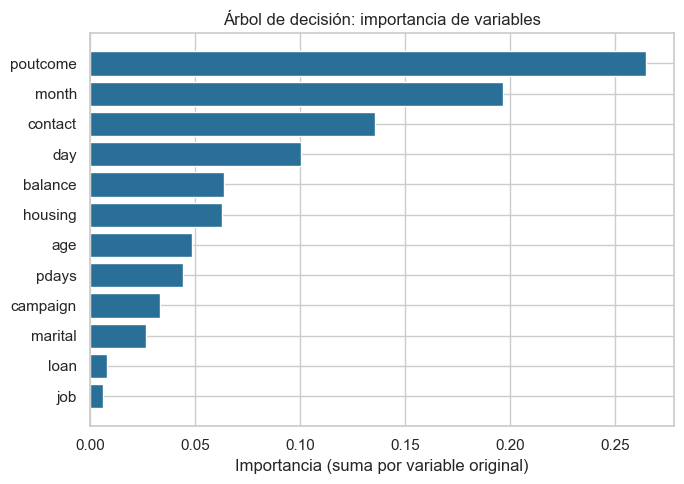

In [14]:
nombres_columnas = [n.split("__", 1)[1] for n in arbol_final.named_steps["prep"].get_feature_names_out()]
plt.figure(figsize=(18, 8))
plot_tree(clf_arbol, max_depth=3, feature_names=nombres_columnas, class_names=["no", "yes"],
          filled=True, rounded=True, fontsize=8, proportion=True, impurity=False)
plt.title("Primeros tres niveles del árbol de decisión")
plt.tight_layout()
guardar("04_arbol_estructura")
plt.show()

importancia_arbol = importancia_por_variable(arbol_final.named_steps["prep"], clf_arbol.feature_importances_)
resultados["Arbol"]["importancia"] = {k: float(v) for k, v in importancia_arbol.items()}
persistir()
print(importancia_arbol.head(10).round(4))
graficar_importancia(importancia_arbol, "Árbol de decisión: importancia de variables", "04_arbol_importancia", "#2a6f97")

**Lectura.** El árbol se apoya sobre todo en `poutcome` (26,5 %), `month` (19,7 %) y `contact` (13,6 %),
y la primera pregunta que hace es si la campaña anterior tuvo éxito (`poutcome_success`). En el
diagrama los valores aparecen como proporciones con el peso de clases aplicado, por eso la raíz muestra
0,5 y 0,5 aunque los contratadores sean el 11,7 % real. Las ramas que concentran más clientes
prometedores combinan campaña previa exitosa con no tener crédito de vivienda. El árbol es la única
familia que se puede explicar a un gerente como reglas.

# Bloque 3: Random Forest (bagging) y evaluación out-of-bag

### Decisiones de diseño

**Por qué Random Forest y no solo bagging.** El bagging promedia árboles entrenados con remuestreos
distintos, y eso reduce la varianza. Random Forest añade un paso más: en cada división solo considera
un subconjunto aleatorio de variables (`max_features`), lo que decorrelaciona los árboles y hace que
el promedio reduzca más varianza. Es la versión del bagging que se usa en la práctica.

**Evaluación out-of-bag (OOB).** Cada árbol se entrena con un remuestreo en el que queda sin usar,
en promedio, el 36,8 % de las filas. Cada fila se predice con los árboles que no la vieron, y eso da
una estimación honesta del desempeño sin separar un conjunto de validación. Hice la búsqueda de
hiperparámetros **con OOB** y no con validación cruzada, porque es más barato (un solo ajuste por
combinación) y es la técnica propia de este modelo.

**Hiperparámetros.** Exploré `max_features` (cuántas variables ve cada división) y `min_samples_leaf`
(el límite del tamaño de las hojas, que controla qué tan profundos y ruidosos son los árboles). Fijé el
número de árboles en 300 y lo verifiqué después con la curva OOB.

**Ponderación.** `class_weight="balanced_subsample"` recalcula los pesos dentro de cada remuestreo, que
es la forma correcta de ponderar en un bosque.

In [15]:
preparador_rf = prep_sin_escalar().fit(X_train)
Xt_rf = preparador_rf.transform(X_train)

def ajustar_rf(maximo, hoja, peso="balanced_subsample", arboles=300, nucleos=-1, semilla=RANDOM_STATE):
    return RandomForestClassifier(n_estimators=arboles, max_features=maximo, min_samples_leaf=hoja,
                                  class_weight=peso, oob_score=True, n_jobs=nucleos,
                                  random_state=semilla).fit(Xt_rf, y_train)

def resumen_oob(bosque):
    oob = np.nan_to_num(bosque.oob_decision_function_[:, 1], nan=0.0)
    return float(f1_score(y_train, oob > 0.5)), float(roc_auc_score(y_train, oob)), float(bosque.oob_score_)

filas = []
for maximo in ["sqrt", 0.2, 0.4]:
    for hoja in [1, 3, 5, 10, 20]:
        inicio = time.perf_counter()
        bosque = ajustar_rf(maximo, hoja)
        f1_oob, auc_oob, acc_oob = resumen_oob(bosque)
        filas.append({"max_features": maximo, "min_samples_leaf": hoja, "f1_oob": f1_oob,
                      "auc_oob": auc_oob, "accuracy_oob": acc_oob, "segundos": time.perf_counter() - inicio})

busqueda_rf = pd.DataFrame(filas)
print(busqueda_rf.round(4).to_string(index=False))
mejor_rf = busqueda_rf.loc[busqueda_rf["f1_oob"].idxmax()]
print("\nMejor combinación según F1 OOB:")
print(mejor_rf.to_string())

max_features  min_samples_leaf  f1_oob  auc_oob  accuracy_oob  segundos
        sqrt                 1  0.3151   0.7784        0.8929   39.7470
        sqrt                 3  0.4722   0.7939        0.8748   23.3838
        sqrt                 5  0.4783   0.7971        0.8635   20.4428
        sqrt                10  0.4696   0.7968        0.8478   18.3562
        sqrt                20  0.4484   0.7934        0.8287   14.7848
         0.2                 1  0.3211   0.7820        0.8927   44.2767
         0.2                 3  0.4646   0.7925        0.8800   32.9439
         0.2                 5  0.4797   0.7963        0.8697   30.4010
         0.2                10  0.4726   0.7974        0.8542   26.2737
         0.2                20  0.4586   0.7961        0.8382   21.8430
         0.4                 1  0.3299   0.7814        0.8932   73.7531
         0.4                 3  0.4451   0.7888        0.8851   54.5960
         0.4                 5  0.4740   0.7907        0.8757   

**Lectura.** El OOB descubre algo que la ponderación sola no arregla, el tamaño de las hojas. Con hojas
de un solo cliente, el F1 OOB es de solo 0,32 a 0,33 (el bosque memoriza, y sus probabilidades casi
nunca pasan de 0,5). Subir `min_samples_leaf` a 3 o 5 lleva el F1 OOB a un valor entre 0,45 y 0,48. La mejor
combinación es `max_features = 0,2` y `min_samples_leaf = 5` (F1 OOB 0,480 y AUC OOB 0,796), aunque las
diferencias entre las combinaciones con hojas de 5 a 10 son de uno o dos puntos y están dentro del
ruido. Usar el 40 % de las variables en cada división casi triplica el tiempo sin mejorar el resultado.

### Del árbol al bagging y al Random Forest

Para ver qué aporta cada paso, comparé tres modelos. Un árbol sin control memoriza el entrenamiento. El
**bagging** promedia muchos árboles de ese tipo, cada uno entrenado con un remuestreo, y eso reduce la
varianza. El **Random Forest** agrega además la selección aleatoria de variables en cada división. Los
medí con la misma métrica fuera de muestra (validación cruzada para el árbol, OOB para los conjuntos).

In [16]:
bagging_puro = BaggingClassifier(
    estimator=DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    n_estimators=100, oob_score=True, n_jobs=-1, random_state=RANDOM_STATE).fit(Xt_rf, y_train)
oob_bagging = np.nan_to_num(bagging_puro.oob_decision_function_[:, 1], nan=0.0)

arbol_libre = cv_arbol[(cv_arbol["param_clf__criterion"] == "entropy") & (cv_arbol["param_clf__max_depth"].isna())
                       & (cv_arbol["param_clf__min_samples_leaf"] == 1)].iloc[0]
mejor_bosque = busqueda_rf.loc[busqueda_rf["f1_oob"].idxmax()]
pd.DataFrame({
    "f1": [arbol_libre["mean_test_f1"], f1_score(y_train, oob_bagging > 0.5), mejor_bosque["f1_oob"]],
    "roc_auc": [arbol_libre["mean_test_roc_auc"], roc_auc_score(y_train, oob_bagging), mejor_bosque["auc_oob"]],
}, index=["árbol sin control (validación cruzada)", "bagging de 100 árboles sin control (OOB)",
          "Random Forest ajustado (OOB)"]).round(4)

,f1,roc_auc
árbol sin control (validación cruzada),0.3108,0.6105
bagging de 100 árboles sin control (OOB),0.3435,0.7623
Random Forest ajustado (OOB),0.4797,0.7963


**Lectura.** La tabla muestra qué aporta cada paso. El árbol sin control obtiene un F1 de 0,311 y un AUC de
0,611 fuera de muestra. Promediar 100 de esos árboles con bagging sube el AUC a 0,762 (la varianza baja
mucho) y el F1 a 0,344. El Random Forest ajustado llega a 0,480 y 0,796, es decir, la selección aleatoria
de variables y el control del tamaño de las hojas aportan otro salto grande sobre el bagging puro.

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\04_rf_curva_oob.png


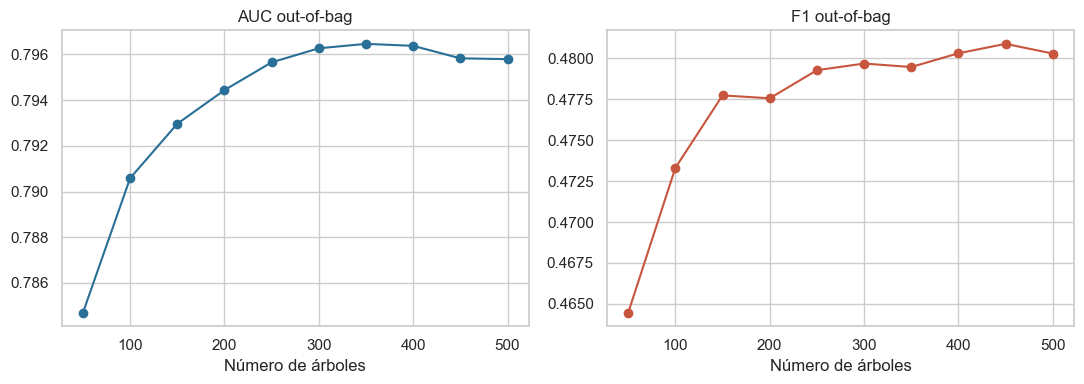

 arboles  f1_oob  auc_oob
      50  0.4644   0.7847
     100  0.4733   0.7906
     150  0.4777   0.7930
     200  0.4776   0.7944
     250  0.4793   0.7957
     300  0.4797   0.7963
     350  0.4795   0.7965
     400  0.4803   0.7964
     450  0.4809   0.7958
     500  0.4803   0.7958


In [17]:
maximo_rf = mejor_rf["max_features"] if mejor_rf["max_features"] == "sqrt" else float(mejor_rf["max_features"])
hoja_rf = int(mejor_rf["min_samples_leaf"])

curva_rf = RandomForestClassifier(max_features=maximo_rf, min_samples_leaf=hoja_rf, class_weight="balanced_subsample",
                                  oob_score=True, warm_start=True, n_jobs=-1, random_state=RANDOM_STATE)
filas = []
for arboles in range(50, 501, 50):
    curva_rf.set_params(n_estimators=arboles).fit(Xt_rf, y_train)
    f1_oob, auc_oob, _ = resumen_oob(curva_rf)
    filas.append({"arboles": arboles, "f1_oob": f1_oob, "auc_oob": auc_oob})
curva_rf = pd.DataFrame(filas)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].plot(curva_rf["arboles"], curva_rf["auc_oob"], marker="o", color="#2a6f97")
ejes[0].set_title("AUC out-of-bag")
ejes[1].plot(curva_rf["arboles"], curva_rf["f1_oob"], marker="o", color="#c8553d")
ejes[1].set_title("F1 out-of-bag")
for eje in ejes:
    eje.set_xlabel("Número de árboles")
plt.tight_layout()
guardar("04_rf_curva_oob")
plt.show()
print(curva_rf.round(4).to_string(index=False))

**Lectura.** El AUC OOB deja de mejorar alrededor de 250 árboles (0,7957) y se mantiene en 0,796 hasta
500, igual que el F1 OOB (0,479 a 0,480). Los 300 árboles elegidos están en la meseta, y agregar más
solo encarecería el modelo.

### Efecto de la ponderación (con OOB)

Con la mejor combinación comparé el bosque ponderado contra uno sin ponderar usando la misma métrica
OOB. No hizo falta validación cruzada porque el OOB ya es una estimación fuera de muestra.

In [18]:
filas = []
for etiqueta, peso in [("sin ponderar", None), ("balanced_subsample", "balanced_subsample")]:
    bosque = ajustar_rf(maximo_rf, hoja_rf, peso=peso)
    oob = np.nan_to_num(bosque.oob_decision_function_[:, 1], nan=0.0)
    filas.append({"ponderación": etiqueta, "f1_oob": f1_score(y_train, oob > 0.5),
                  "recall_oob": recall_score(y_train, oob > 0.5), "precision_oob": precision_score(y_train, oob > 0.5),
                  "auc_oob": roc_auc_score(y_train, oob)})
pd.DataFrame(filas).set_index("ponderación").round(4)

,f1_oob,recall_oob,precision_oob,auc_oob
ponderación,,,,
sin ponderar,0.3085,0.2014,0.6594,0.7956
balanced_subsample,0.4797,0.5136,0.4500,0.7963


**Lectura.** Sin ponderar, el bosque predice muy pocos contratadores (recall OOB de 0,201, precisión
de 0,659, F1 de 0,309). Con `balanced_subsample` el F1 sube a 0,480 y el recall a 0,514. El AUC es casi
igual en ambos (0,796), lo que indica que la ponderación mueve el punto de operación pero no cambia
lo bien que el bosque ordena a los clientes.

### Modelo final, costo, OOB frente a prueba y estabilidad

Ajusté el modelo final como `Pipeline` completo con un solo núcleo para medir el costo. Cerré el bloque
con dos verificaciones. La primera compara la estimación OOB con el resultado en prueba, ya que si el OOB
es un buen estimador las dos cifras deben quedar cerca. La segunda mide la estabilidad, para lo que
reentrené el bosque con cinco semillas distintas y medí cuánto cambian el F1 y el AUC en prueba.

In [19]:
def construir_rf():
    return Pipeline([
        ("prep", prep_sin_escalar()),
        ("clf", RandomForestClassifier(n_estimators=300, max_features=maximo_rf, min_samples_leaf=hoja_rf,
                                       class_weight="balanced_subsample", oob_score=True, n_jobs=1,
                                       random_state=RANDOM_STATE))])

rf_final, segundos_rf, rango_rf = ajustar_midiendo(construir_rf)

f1_oob_final, auc_oob_final, acc_oob_final = resumen_oob(rf_final.named_steps["clf"])
registrar("RandomForest", rf_final, segundos_rf, 5, 0.5,
          extra={"rango_entrenamiento_s": rango_rf, "parametros": {"max_features": str(maximo_rf), "min_samples_leaf": hoja_rf, "n_estimators": 300},
                 "oob": {"f1": f1_oob_final, "roc_auc": auc_oob_final, "accuracy": acc_oob_final}})
print(f"OOB -> F1 {f1_oob_final:.4f} | AUC {auc_oob_final:.4f}   frente a   prueba -> "
      f"F1 {resultados['RandomForest']['test']['f1']:.4f} | AUC {resultados['RandomForest']['test']['roc_auc']:.4f}")

RandomForest: entrenamiento 113.92 s | predicción 0.551 s
  test -> accuracy 0.8732 | precision 0.4621 | recall 0.5132 | F1 0.4863 | AUC 0.8043
  train (muestra) -> F1 0.6943 | AUC 0.9653
  IC 95 % F1 0.4601 a 0.5123 | captura top 20 % 0.626
OOB -> F1 0.4797 | AUC 0.7963   frente a   prueba -> F1 0.4863 | AUC 0.8043


**Lectura.** El Random Forest obtiene el mejor F1 (0,486) y el mejor AUC (0,804) de los cuatro. La
estimación OOB (F1 de 0,480 y AUC de 0,796) quedó muy cerca del resultado en prueba, lo que confirma
que el OOB sirve como validación sin separar datos. Pero el bosque tiene la mayor brecha de sobreajuste
(AUC de 0,965 sobre entrenamiento contra 0,804 en prueba, y F1 de 0,694 contra 0,486), porque los
árboles profundos memorizan, y el promedio solo corrige parte de ese efecto. Su costo de entrenamiento
con un solo núcleo es de casi dos minutos, comparable al del SVM, y la predicción tarda medio
segundo.

             f1     auc
semilla                
1        0.4870  0.8047
7        0.4915  0.8045
21       0.4906  0.8045
42       0.4863  0.8043
99       0.4881  0.8051

Media: {'f1': 0.4887, 'auc': 0.8046} | Desviación: {'f1': 0.0023, 'auc': 0.0003}

 balance     0.1397
month       0.1289
age         0.1215
day         0.1070
poutcome    0.0809
contact     0.0770
job         0.0708
campaign    0.0568
pdays       0.0495
housing     0.0418
dtype: float64


Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\04_rf_importancia.png


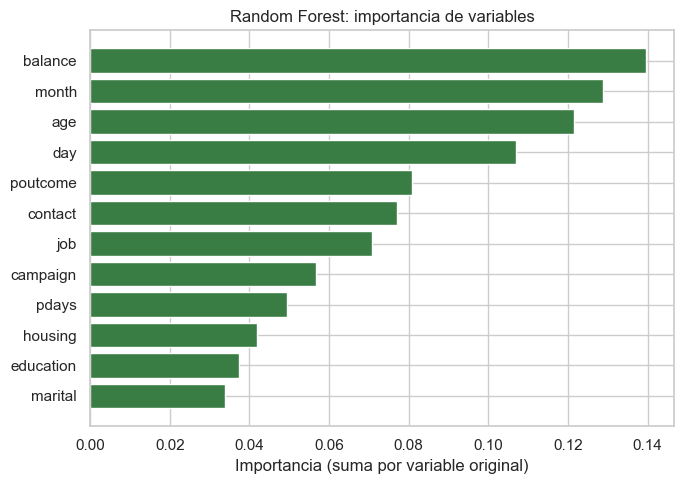

In [20]:
Xt_prueba_rf = preparador_rf.transform(X_test)
filas = []
for semilla in [1, 7, 21, 42, 99]:
    bosque = ajustar_rf(maximo_rf, hoja_rf, semilla=semilla)
    prediccion = bosque.predict(Xt_prueba_rf)
    filas.append({"semilla": semilla, "f1": f1_score(y_test, prediccion),
                  "auc": roc_auc_score(y_test, bosque.predict_proba(Xt_prueba_rf)[:, 1])})
estabilidad_rf = pd.DataFrame(filas).set_index("semilla")
print(estabilidad_rf.round(4))
print("\nMedia:", estabilidad_rf.mean().round(4).to_dict(), "| Desviación:", estabilidad_rf.std().round(4).to_dict())
resultados["RandomForest"]["estabilidad_semillas"] = {"f1_media": float(estabilidad_rf["f1"].mean()),
    "f1_desv": float(estabilidad_rf["f1"].std()), "auc_media": float(estabilidad_rf["auc"].mean()),
    "auc_desv": float(estabilidad_rf["auc"].std())}

importancia_rf = importancia_por_variable(rf_final.named_steps["prep"], rf_final.named_steps["clf"].feature_importances_)
resultados["RandomForest"]["importancia"] = {k: float(v) for k, v in importancia_rf.items()}
persistir()
print("\n", importancia_rf.head(10).round(4))
graficar_importancia(importancia_rf, "Random Forest: importancia de variables", "04_rf_importancia", "#3a7d44")

**Lectura.** Con cinco semillas distintas el F1 en prueba varía entre 0,486 y 0,492 (desviación de
0,002) y el AUC prácticamente no cambia (desviación de 0,0003). El bosque es muy estable frente a la
aleatoriedad del remuestreo. En importancia de variables aparecen primero `balance` (14,0 %), `month`
(12,9 %), `age` (12,2 %) y `day` (10,7 %). Esta medida (reducción de impureza) favorece a las variables
numéricas con muchos valores distintos, porque ofrecen más umbrales posibles, y por eso `balance`, `age` y
`day` aparecen más arriba que en el árbol y el boosting.


**Criterios de selección del bloque.** Dentro del bosque, la combinación se eligió por F1 OOB (con el AUC OOB
como desempate), porque mide fuera de muestra sin gastar datos de validación. Como modelo, el bosque se
juzga con cuatro criterios. En rendimiento es el primero (F1 de 0,486 y AUC de 0,804). En estabilidad es
excelente frente a la semilla (desviación de 0,002 en F1) pero tiene la mayor brecha entre entrenamiento
y prueba. En costo, entrena y predice en cientos de segundos y en poco más de un segundo
respectivamente. En interpretabilidad solo ofrece importancias de variables, no reglas.

# Bloque 4: XGBoost (boosting)

### Decisiones de diseño

**Qué cambia respecto al bagging.** Un bosque entrena árboles independientes y los promedia; el
boosting entrena árboles **en secuencia**, cada uno corrigiendo los errores del conjunto anterior.
Eso reduce el sesgo (puede construir fronteras que un árbol suelto no alcanza) pero, si se deja correr
sin freno, acaba memorizando el ruido. Por eso aquí el control del sobreajuste es parte central del
diseño.

**Hiperparámetros.** `learning_rate` (cuánto aporta cada árbol: valores bajos exigen más árboles pero
generalizan mejor), `max_depth` (complejidad de cada árbol; en boosting conviene que sean poco
profundos) y `n_estimators`, que **no se busca en rejilla** sino con *early stopping*. `subsample` y
`colsample_bytree` se fijan en 0,8, que agrega aleatoriedad y regulariza.

**Early stopping.** Separé de entrenamiento una partición interna de validación (15 %, estratificada).
Entrené con un número de árboles muy alto (3000) y detuve el entrenamiento cuando el AUC de validación
no mejoró durante 50 rondas, con lo que el mejor número de árboles quedó registrado. El conjunto de
prueba no intervino.

**Ponderación.** `scale_pos_weight` igual a la razón entre clases (aproximadamente 7,55) es el
equivalente de `class_weight="balanced"` en XGBoost.

**Selección.** El early stopping de cada combinación usó AUC, pero entre combinaciones elegí la que dio
mayor F1 de la clase positiva en la partición de validación, para ser coherente con los demás modelos.

**Modelo final.** Reentrené sobre todo el entrenamiento con el número de árboles encontrado
multiplicado por 1,1, porque el modelo final ve un 17 % más de datos que el de la búsqueda.

In [21]:
preparador_xgb = prep_sin_escalar().fit(X_train)
Xt_xgb = preparador_xgb.transform(X_train)
Xt_prueba_xgb = preparador_xgb.transform(X_test)
Xi, Xv, yi, yv = train_test_split(Xt_xgb, y_train, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE)

def ajustar_xgb(tasa, profundidad, peso_pos):
    modelo = XGBClassifier(n_estimators=3000, learning_rate=tasa, max_depth=profundidad, subsample=0.8,
                           colsample_bytree=0.8, scale_pos_weight=peso_pos, eval_metric="auc",
                           early_stopping_rounds=50, tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE)
    modelo.fit(Xi, yi, eval_set=[(Xi, yi), (Xv, yv)], verbose=False)
    return modelo

filas, modelos_busqueda = [], {}
for tasa in [0.03, 0.1, 0.3]:
    for profundidad in [2, 3, 4, 6]:
        inicio = time.perf_counter()
        modelo = ajustar_xgb(tasa, profundidad, peso_positivo)
        proba = modelo.predict_proba(Xv)[:, 1]
        filas.append({"learning_rate": tasa, "max_depth": profundidad, "arboles_optimos": modelo.best_iteration + 1,
                      "auc_validacion": modelo.best_score, "f1_validacion": f1_score(yv, proba > 0.5),
                      "segundos": time.perf_counter() - inicio})
        modelos_busqueda[(tasa, profundidad)] = modelo

busqueda_xgb = pd.DataFrame(filas)
print(busqueda_xgb.round(4).to_string(index=False))
mejor_xgb = busqueda_xgb.loc[busqueda_xgb["f1_validacion"].idxmax()]
print("\nMejor combinación según F1 de validación:")
print(mejor_xgb.round(4).to_string())

 learning_rate  max_depth  arboles_optimos  auc_validacion  f1_validacion  segundos
          0.03          2              806          0.8129         0.4416   25.8005
          0.03          3              483          0.8141         0.4485   16.7674
          0.03          4              410          0.8155         0.4577   14.7284
          0.03          6              266          0.8153         0.4658   10.3741
          0.10          2              320          0.8154         0.4460   11.4738
          0.10          3              198          0.8150         0.4524    6.8632
          0.10          4              114          0.8156         0.4554    4.9310
          0.10          6               58          0.8141         0.4633    3.4831
          0.30          2              114          0.8152         0.4514    4.2487
          0.30          3               63          0.8146         0.4553    3.5964
          0.30          4               40          0.8121         0.4531   

**Lectura.** Las doce combinaciones tienen un AUC de validación parecido (0,804 a 0,816), una diferencia
pequeña, y el F1 de validación va de 0,442 a 0,466. Lo que sí cambia mucho es la cantidad de árboles que
pide el early stopping. Con `learning_rate = 0,03` llega a 806 árboles si la profundidad es 2, y con 0,3
y profundidad 6 se detiene en 29. La mejor combinación por F1 es `learning_rate = 0,03` y `max_depth = 6`
con 266 árboles. La tasa baja necesita más árboles para llegar a una calidad similar.

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\04_xgb_early_stopping.png


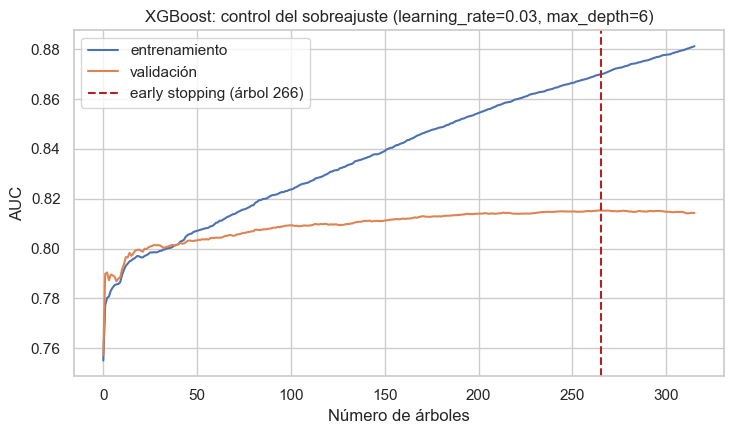

In [22]:
tasa_xgb = float(mejor_xgb["learning_rate"])
profundidad_xgb = int(mejor_xgb["max_depth"])
modelo_elegido = modelos_busqueda[(tasa_xgb, profundidad_xgb)]
curvas = modelo_elegido.evals_result()
mejor_ronda = modelo_elegido.best_iteration

plt.figure(figsize=(7.5, 4.5))
plt.plot(curvas["validation_0"]["auc"], label="entrenamiento")
plt.plot(curvas["validation_1"]["auc"], label="validación")
plt.axvline(mejor_ronda, color="firebrick", linestyle="--", label=f"early stopping (árbol {mejor_ronda + 1})")
plt.xlabel("Número de árboles")
plt.ylabel("AUC")
plt.title(f"XGBoost: control del sobreajuste (learning_rate={tasa_xgb}, max_depth={profundidad_xgb})")
plt.legend()
plt.tight_layout()
guardar("04_xgb_early_stopping")
plt.show()

**Lectura.** La curva de entrenamiento sigue subiendo (AUC cerca de 0,88) mientras la de validación se
aplana en 0,815 y empieza a bajar después del árbol 266, que es donde se detiene el entrenamiento. La
distancia entre ambas curvas es el sobreajuste que el early stopping evita seguir ampliando.

### Efecto de la ponderación

Con la mejor combinación volví a correr el early stopping sin ponderar (`scale_pos_weight=1`) y comparé
en la misma partición de validación.

In [23]:
filas = []
for etiqueta, peso in [("sin ponderar (1)", 1.0), (f"scale_pos_weight ({peso_positivo:.2f})", peso_positivo)]:
    modelo = ajustar_xgb(tasa_xgb, profundidad_xgb, peso)
    proba = modelo.predict_proba(Xv)[:, 1]
    filas.append({"ponderación": etiqueta, "f1": f1_score(yv, proba > 0.5), "recall": recall_score(yv, proba > 0.5),
                  "precision": precision_score(yv, proba > 0.5), "auc": roc_auc_score(yv, proba)})
pd.DataFrame(filas).set_index("ponderación").round(4)

,f1,recall,precision,auc
ponderación,,,,
sin ponderar (1),0.3329,0.2205,0.6796,0.8153
scale_pos_weight (7.55),0.4658,0.6378,0.3668,0.8153


**Lectura.** Igual que en los otros modelos, `scale_pos_weight` mueve el punto de operación sin cambiar
el ordenamiento. El AUC es idéntico (0,815), pero el recall pasa de 0,221 a 0,638 y el F1 de 0,333 a
0,466. Conservé la ponderación.

### Modelo final, costo y estabilidad

Ajusté el `Pipeline` completo con el número de árboles ya fijado (sin early stopping, porque no hay
partición de validación en este paso) y un solo núcleo. Después lo reentrené con cinco semillas para
medir la estabilidad.

In [24]:
arboles_finales = int((mejor_ronda + 1) * 1.1)
parametros_xgb = dict(n_estimators=arboles_finales, learning_rate=tasa_xgb, max_depth=profundidad_xgb, subsample=0.8,
                      colsample_bytree=0.8, scale_pos_weight=peso_positivo, tree_method="hist")

def construir_xgb():
    return Pipeline([
        ("prep", prep_sin_escalar()),
        ("clf", XGBClassifier(**parametros_xgb, n_jobs=1, random_state=RANDOM_STATE))])

xgb_final, segundos_xgb, rango_xgb = ajustar_midiendo(construir_xgb)

registrar("XGBoost", xgb_final, segundos_xgb, 5, 0.5,
          extra={"rango_entrenamiento_s": rango_xgb, "parametros": {"learning_rate": tasa_xgb, "max_depth": profundidad_xgb, "n_estimators": arboles_finales,
                                "arboles_early_stopping": int(mejor_ronda + 1), "subsample": 0.8, "colsample_bytree": 0.8,
                                "scale_pos_weight": peso_positivo}})

XGBoost: entrenamiento 2.57 s | predicción 0.158 s
  test -> accuracy 0.8246 | precision 0.3576 | recall 0.6267 | F1 0.4554 | AUC 0.8039
  train (muestra) -> F1 0.4939 | AUC 0.8617
  IC 95 % F1 0.4334 a 0.4768 | captura top 20 % 0.623


**Lectura.** XGBoost obtiene un F1 de 0,455 y un AUC de 0,804 en prueba, el mismo AUC que el Random
Forest, con un recall más alto (0,627 contra 0,513) y una precisión menor (0,358 contra 0,462). Lo
importante es el costo. Entrena en unos pocos segundos con un solo núcleo, entre cuarenta y cincuenta veces más
rápido que el SVM y el Random Forest, y predice los 9.043 clientes en una fracción de segundo. Su brecha
de sobreajuste (AUC de 0,862 contra 0,804) es moderada.

             f1     auc
semilla                
1        0.4544  0.8040
7        0.4592  0.8048
21       0.4600  0.8045
42       0.4582  0.8053
99       0.4638  0.8057

Media: {'f1': 0.4591, 'auc': 0.8049} | Desviación: {'f1': 0.0034, 'auc': 0.0007}

 month        0.3157
poutcome     0.2358
contact      0.1601
job          0.0800
housing      0.0450
marital      0.0384
education    0.0283
loan         0.0172
pdays        0.0150
age          0.0116
dtype: float64


Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\04_xgb_importancia.png


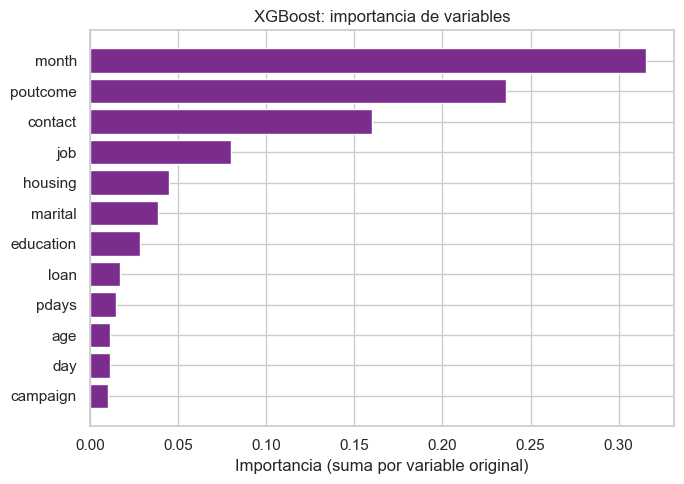

In [25]:
filas = []
for semilla in [1, 7, 21, 42, 99]:
    modelo = XGBClassifier(**parametros_xgb, n_jobs=-1, random_state=semilla).fit(Xt_xgb, y_train)
    proba = modelo.predict_proba(Xt_prueba_xgb)[:, 1]
    filas.append({"semilla": semilla, "f1": f1_score(y_test, proba > 0.5), "auc": roc_auc_score(y_test, proba)})
estabilidad_xgb = pd.DataFrame(filas).set_index("semilla")
print(estabilidad_xgb.round(4))
print("\nMedia:", estabilidad_xgb.mean().round(4).to_dict(), "| Desviación:", estabilidad_xgb.std().round(4).to_dict())
resultados["XGBoost"]["estabilidad_semillas"] = {"f1_media": float(estabilidad_xgb["f1"].mean()),
    "f1_desv": float(estabilidad_xgb["f1"].std()), "auc_media": float(estabilidad_xgb["auc"].mean()),
    "auc_desv": float(estabilidad_xgb["auc"].std())}

importancia_xgb = importancia_por_variable(xgb_final.named_steps["prep"], xgb_final.named_steps["clf"].feature_importances_)
resultados["XGBoost"]["importancia"] = {k: float(v) for k, v in importancia_xgb.items()}
persistir()
print("\n", importancia_xgb.head(10).round(4))
graficar_importancia(importancia_xgb, "XGBoost: importancia de variables", "04_xgb_importancia", "#7b2d8e")

**Lectura.** Con cinco semillas el F1 en prueba varía entre 0,454 y 0,464 (desviación de 0,003) y el AUC
entre 0,804 y 0,806. Es estable, un poco menos que el bosque en F1. En importancia domina `month`
(31,6 %), seguido de `poutcome` (23,6 %) y `contact` (16,0 %), las tres variables de contexto de la
campaña. Las variables numéricas pesan poco en este modelo (`balance`, `age` y `day` suman menos del
4 %), al contrario de lo que ocurre en el bosque.


**Criterios de selección del bloque.** Dentro del boosting, la combinación se eligió por F1 en la partición
de validación, mientras que el número de árboles lo fijó el early stopping por AUC. Como modelo, XGBoost
se juzga con cuatro criterios. En rendimiento queda segundo en F1 (0,455) y empatado en AUC (0,804). En
estabilidad varía poco con la semilla (desviación de 0,003 en F1) y su brecha de sobreajuste es
moderada (0,039 en F1). En costo es el segundo más barato, con un entrenamiento de pocos segundos. En
interpretabilidad ofrece importancias de variables claras, aunque no reglas legibles.

## Cierre del notebook

Reuní en una tabla los cuatro modelos y la línea base con todo lo medido en este notebook. El notebook 05
parte de estos mismos archivos para construir la comparación, las figuras y las conclusiones.

In [26]:
filas = []
for nombre, r in resultados.items():
    filas.append({"modelo": nombre, **{k: round(v, 4) for k, v in r["test"].items()},
                  "t_entrenamiento_s": round(r["tiempo_entrenamiento_s"], 3),
                  "t_prediccion_s": round(r["tiempo_prediccion_s"], 4)})
pd.DataFrame(filas).set_index("modelo")

,accuracy,precision,recall,f1,roc_auc,t_entrenamiento_s,t_prediccion_s
modelo,,,,,,,
Baseline,0.8830,0.0000,0.0000,0.0000,0.5000,0.002,0.0001
SVM,0.8276,0.3573,0.5926,0.4458,0.7898,135.275,18.5074
Arbol,0.8143,0.3358,0.6002,0.4307,0.7800,0.599,0.0496
RandomForest,0.8732,0.4621,0.5132,0.4863,0.8043,113.923,0.5511
XGBoost,0.8246,0.3576,0.6267,0.4554,0.8039,2.567,0.1583


**Lectura.** Resumen del notebook. El Random Forest lidera en F1 y AUC, XGBoost iguala su AUC y queda
segundo en F1, el SVM y el árbol cierran la tabla. El costo, en cambio, se ordena distinto. El árbol
es el más barato, XGBoost le sigue, y el SVM y el Random Forest cuestan entre cuarenta y cincuenta veces más que XGBoost y cientos de veces más que el árbol en
entrenamiento. El notebook 05 pondera esas dos dimensiones.